<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


> **Completed by Manuel (GitHub: TrentA21)** — IBM Applied Data Science Capstone, *EDA with Data Visualization* (`edadataviz.ipynb`). All 8 TASKs are filled in, the notebook was executed end-to-end, and every chart is also saved as a PNG in `images/eda/` for the final presentation.

# **SpaceX  Falcon 9 First Stage Landing Prediction**


 ## Assignment: Exploring and Preparing Data


Estimated time needed: **70** minutes


In this assignment, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is due to the fact that SpaceX can reuse the first stage. 

In this lab, you will perform Exploratory Data Analysis and Feature Engineering.


Falcon 9 first stage will land successfully


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planned. Space X performs a controlled landing in the oceans. 


  ## Objectives
Perform exploratory Data Analysis and Feature Engineering using `Pandas` and `Matplotlib`

- Exploratory Data Analysis
- Preparing Data  Feature Engineering 


----


### Import Libraries and Define Auxiliary Functions


We will import the following libraries the lab 



In [1]:
# andas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
#NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns

## Exploratory Data Analysis 


First, let's read the SpaceX dataset into a Pandas dataframe and print its summary


In [2]:
import os
os.makedirs('images/eda', exist_ok=True)
df=pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")

# If you were unable to complete the previous lab correctly you can uncomment and load this csv

# df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/dataset_part_2.csv')

df.head(5)

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the <code>FlightNumber</code> vs. <code>PayloadMass</code>and overlay the outcome of the launch. We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass is also important; it seems the more massive the payload, the less likely the first stage will return.


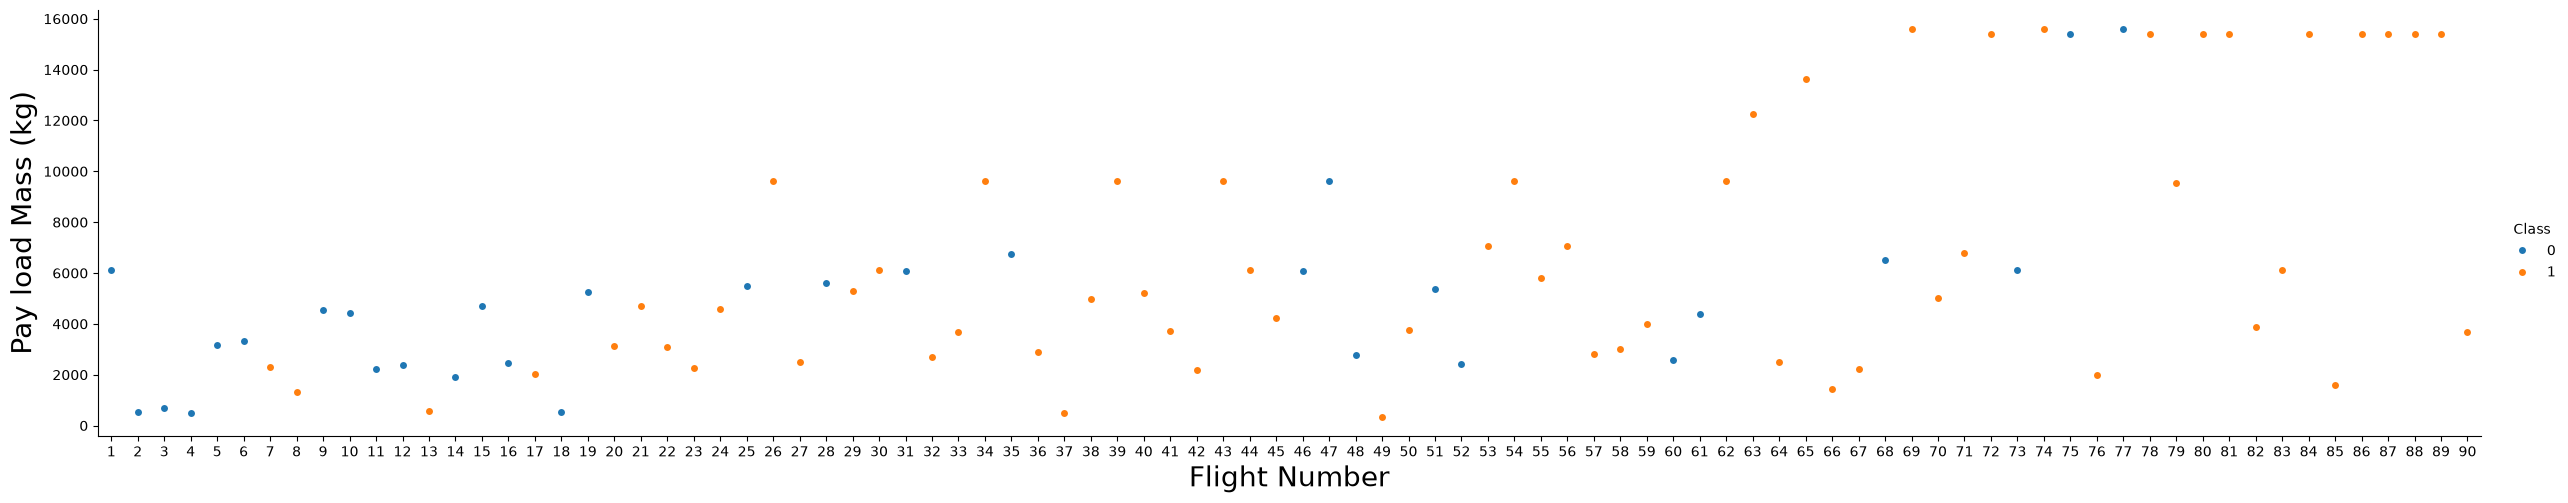

In [3]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect = 5)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Pay load Mass (kg)",fontsize=20)
plt.savefig('images/eda/flightnumber_vs_payload.png', bbox_inches='tight', dpi=120)
plt.show()

> *Explanation:* As flight number grows, more launches land (orange = class 1); heavier payloads look harder to recover in the early flights.

Next, let's drill down to each site visualize its detailed launch records.


### TASK 1: Visualize the relationship between Flight Number and Launch Site


Use the function <code>catplot</code> to plot <code>FlightNumber</code> vs <code>LaunchSite</code>, set the  parameter <code>x</code>  parameter to <code>FlightNumber</code>,set the  <code>y</code> to <code>Launch Site</code> and set the parameter <code>hue</code> to <code>'class'</code>


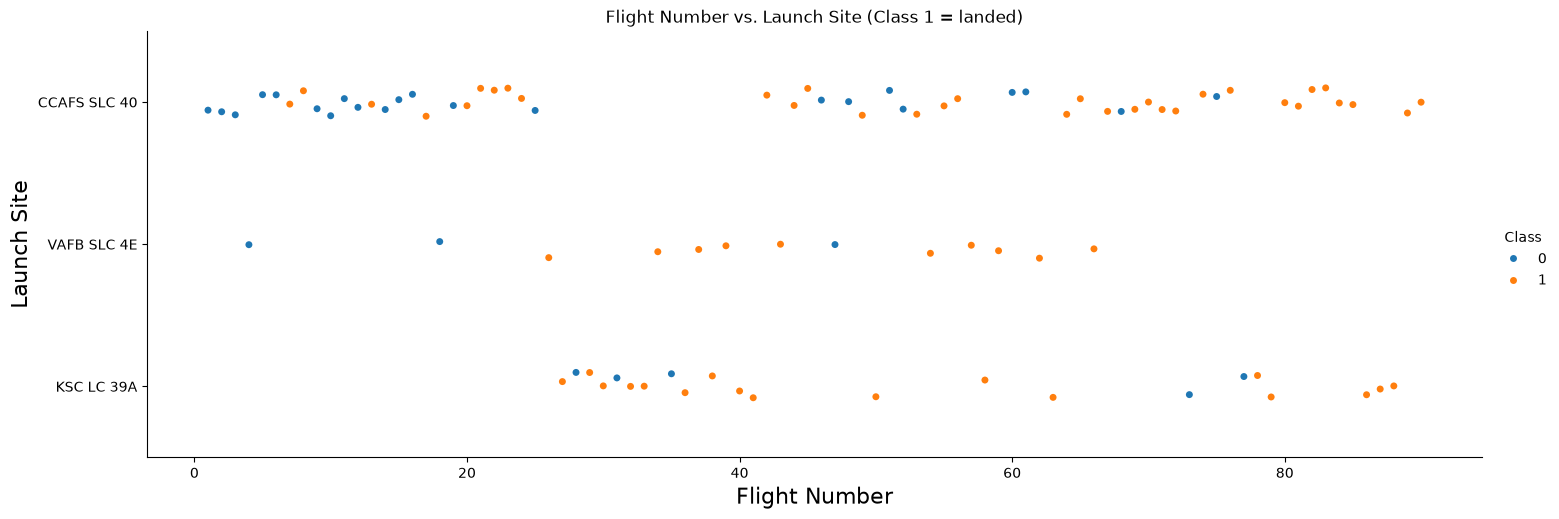

In [4]:
# Plot a scatter point chart with x axis to be Flight Number and y axis to be the launch site, and hue to be the class value
sns.catplot(x="FlightNumber", y="LaunchSite", hue="Class", data=df, aspect=3)
plt.xlabel("Flight Number", fontsize=16)
plt.ylabel("Launch Site", fontsize=16)
plt.title("Flight Number vs. Launch Site (Class 1 = landed)")
plt.savefig('images/eda/task1_flightnumber_vs_launchsite.png', bbox_inches='tight', dpi=120)
plt.show()

> *Explanation (Task 1):* `catplot` draws one dot per launch with flight number on x, site on y and colour = landing outcome. **Pattern:** early flights (mostly from CCAFS SLC 40) failed often; later flights at every site are mostly successful, so experience (flight number) matters. KSC LC 39A was only used from flight ~25 onward and has a high success share; VAFB SLC 4E has few launches but mostly successful.

Now try to explain the patterns you found in the Flight Number vs. Launch Site scatter point plots.


### TASK 2: Visualize the relationship between Payload and Launch Site


We also want to observe if there is any relationship between launch sites and their payload mass.


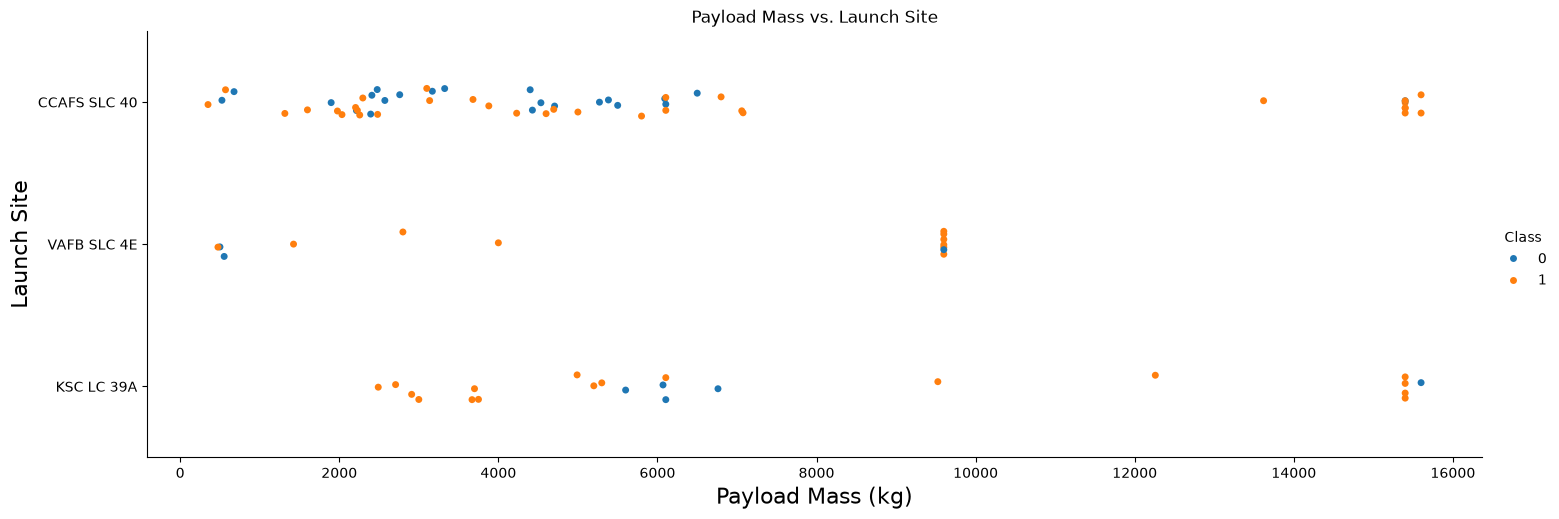

In [5]:
# Plot a scatter point chart with x axis to be Pay Load Mass (kg) and y axis to be the launch site, and hue to be the class value
sns.catplot(x="PayloadMass", y="LaunchSite", hue="Class", data=df, aspect=3)
plt.xlabel("Payload Mass (kg)", fontsize=16)
plt.ylabel("Launch Site", fontsize=16)
plt.title("Payload Mass vs. Launch Site")
plt.savefig('images/eda/task2_payload_vs_launchsite.png', bbox_inches='tight', dpi=120)
plt.show()

> *Explanation (Task 2):* Same idea with payload mass on x. VAFB SLC 4E has no launches with heavy payloads (> 10,000 kg); heavy payloads (> 10,000 kg) launched from CCAFS SLC 40 and KSC LC 39A were mostly successful.

Now if you observe Payload Vs. Launch Site scatter point chart you will find for the VAFB-SLC  launchsite there are no  rockets  launched for  heavypayload mass(greater than 10000).


### TASK  3: Visualize the relationship between success rate of each orbit type


Next, we want to visually check if there are any relationship between success rate and orbit type.


Let's create a `bar chart` for the sucess rate of each orbit


Orbit
ES-L1    1.000
GEO      1.000
HEO      1.000
SSO      1.000
VLEO     0.857
LEO      0.714
PO       0.667
MEO      0.667
ISS      0.619
GTO      0.519
SO       0.000
Name: Class, dtype: float64


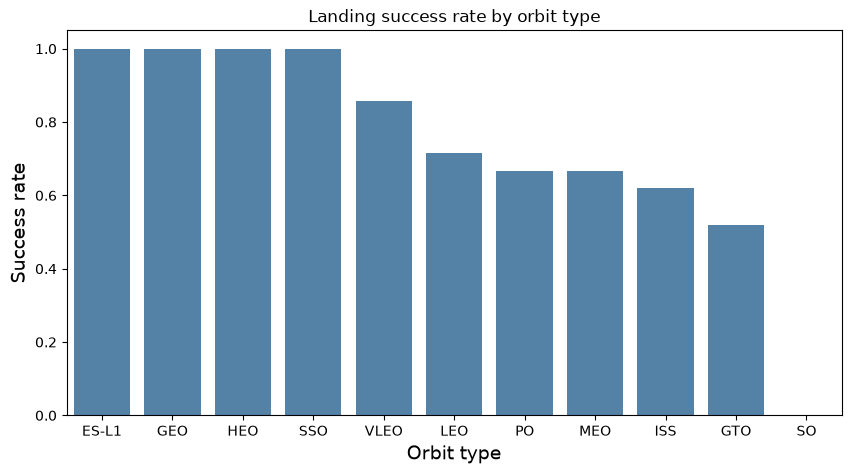

In [6]:
# HINT use groupby method on Orbit column and get the mean of Class column
orbit_success = df.groupby('Orbit')['Class'].mean().sort_values(ascending=False)
print(orbit_success.round(3))
plt.figure(figsize=(10, 5))
sns.barplot(x=orbit_success.index, y=orbit_success.values, color='steelblue')
plt.xlabel("Orbit type", fontsize=14)
plt.ylabel("Success rate", fontsize=14)
plt.title("Landing success rate by orbit type")
plt.savefig('images/eda/task3_success_rate_by_orbit.png', bbox_inches='tight', dpi=120)
plt.show()

> *Explanation (Task 3):* `groupby('Orbit')['Class'].mean()` gives the share of successful landings per orbit. **ES-L1, GEO, HEO and SSO have 100 %** (but only 1–5 launches each), VLEO ≈ 86 %, LEO ≈ 71 %, ISS ≈ 62 %, PO ≈ 67 %, MEO ≈ 67 %, GTO ≈ 52 %, and **SO = 0 %** (1 launch).

Analyze the ploted bar chart try to find which orbits have high sucess rate.


### TASK  4: Visualize the relationship between FlightNumber and Orbit type


For each orbit, we want to see if there is any relationship between FlightNumber and Orbit type.


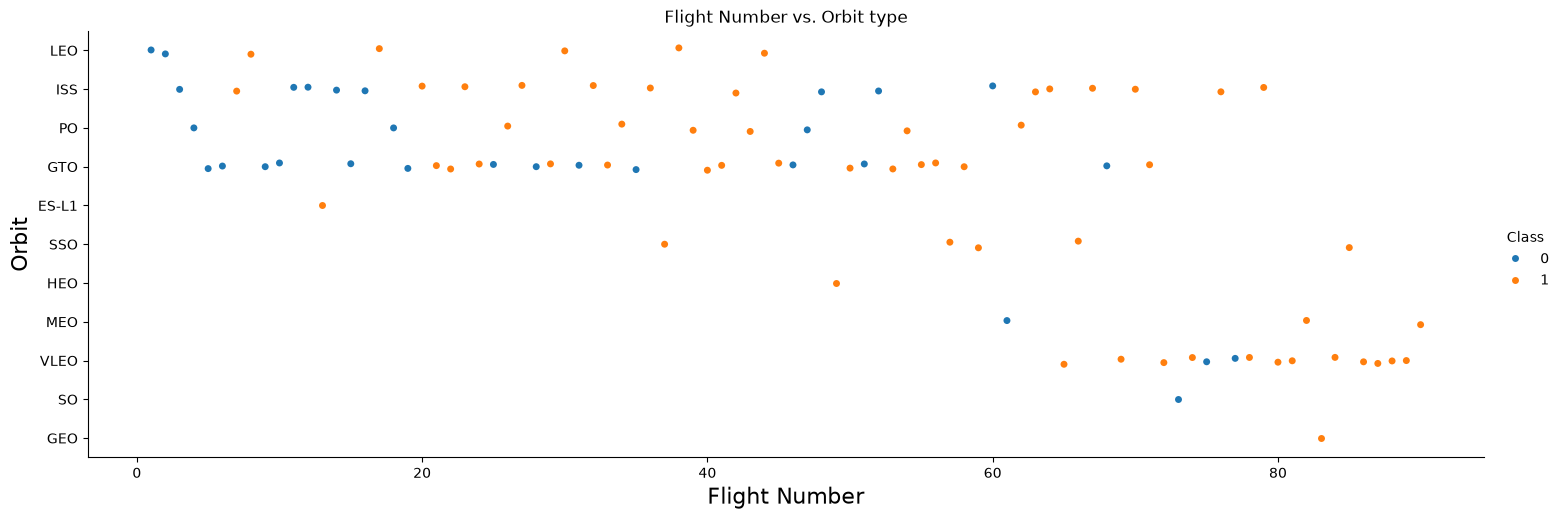

In [7]:
# Plot a scatter point chart with x axis to be FlightNumber and y axis to be the Orbit, and hue to be the class value
sns.catplot(x="FlightNumber", y="Orbit", hue="Class", data=df, aspect=3)
plt.xlabel("Flight Number", fontsize=16)
plt.ylabel("Orbit", fontsize=16)
plt.title("Flight Number vs. Orbit type")
plt.savefig('images/eda/task4_flightnumber_vs_orbit.png', bbox_inches='tight', dpi=120)
plt.show()

> *Explanation (Task 4):* In **LEO**, success seems related to the number of flights (later flights succeed); in **GTO** there is no clear relationship with flight number.

You should see that in the LEO orbit the Success appears related to the number of flights; on the other hand, there seems to be no relationship between flight number when in GTO orbit.


### TASK  5: Visualize the relationship between Payload and Orbit type


Similarly, we can plot the Payload vs. Orbit scatter point charts to reveal the relationship between Payload and Orbit type


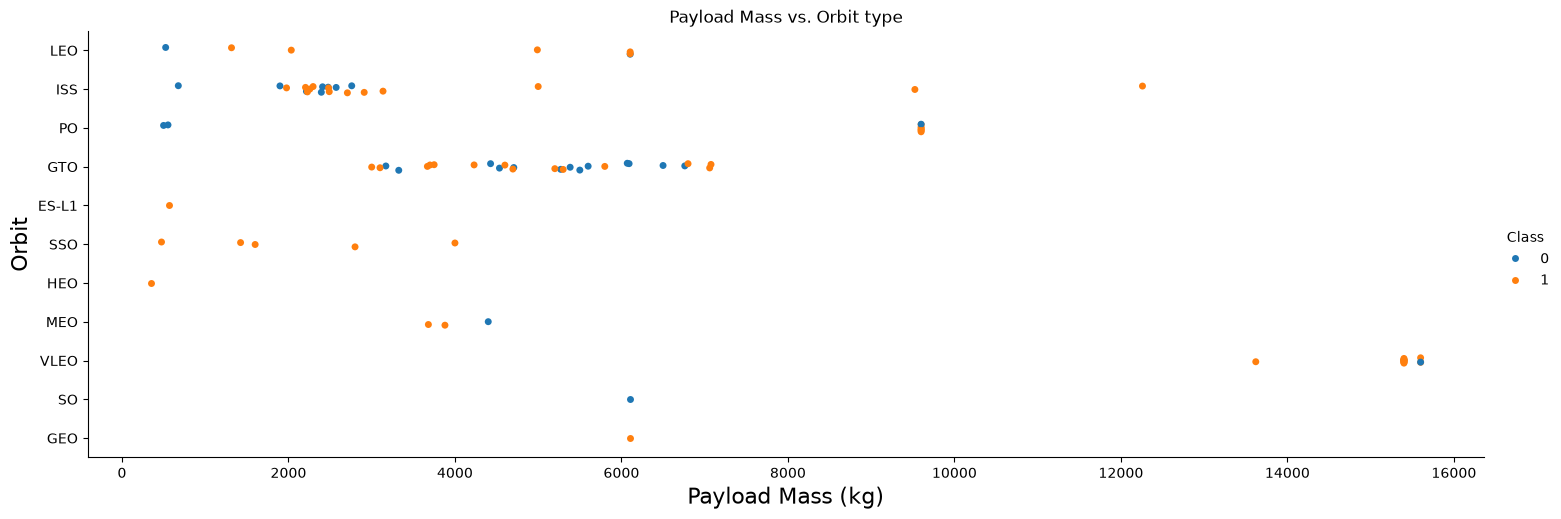

In [8]:
# Plot a scatter point chart with x axis to be Payload Mass and y axis to be the Orbit, and hue to be the class value
sns.catplot(x="PayloadMass", y="Orbit", hue="Class", data=df, aspect=3)
plt.xlabel("Payload Mass (kg)", fontsize=16)
plt.ylabel("Orbit", fontsize=16)
plt.title("Payload Mass vs. Orbit type")
plt.savefig('images/eda/task5_payload_vs_orbit.png', bbox_inches='tight', dpi=120)
plt.show()

> *Explanation (Task 5):* With heavy payloads, successful landings are more common for **Polar (PO), LEO and ISS** orbits. For **GTO** both outcomes appear at all payloads, so payload alone does not separate them.

With heavy payloads the successful landing or positive landing rate are more for Polar,LEO and ISS.   

However for GTO we cannot distinguish this well as both positive landing rate and negative landing(unsuccessful mission) are both there here.




### TASK  6: Visualize the launch success yearly trend


You can plot a line chart with x axis to be <code>Year</code> and y axis to be average success rate, to get the average launch success trend. 


The function will help you get the year from the date:


In [9]:
# A function to Extract years from the date 
year=[]
def Extract_year(date):
    for i in df["Date"]:
        year.append(i.split("-")[0])
    return year
    

Year
2010    0.000
2012    0.000
2013    0.000
2014    0.333
2015    0.333
2016    0.625
2017    0.833
2018    0.611
2019    0.900
2020    0.842
Name: Class, dtype: float64


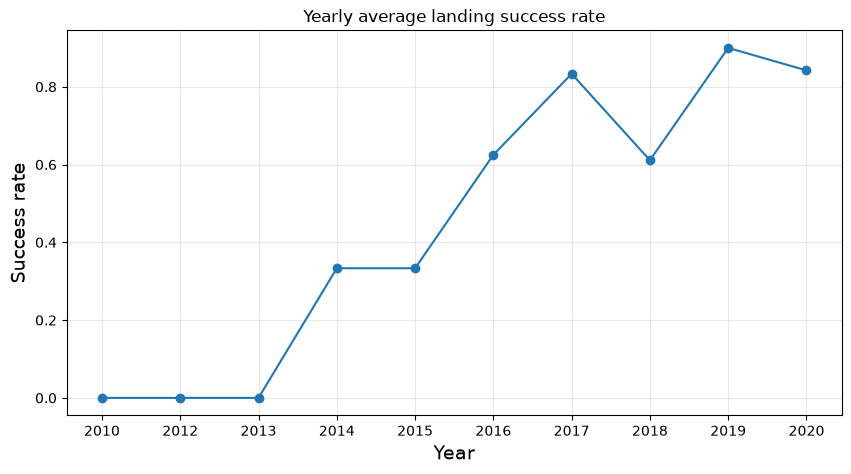

In [10]:
# Plot a line chart with x axis to be the extracted year and y axis to be the success rate
df['Year'] = Extract_year(df["Date"])
yearly = df.groupby('Year')['Class'].mean()
print(yearly.round(3))
plt.figure(figsize=(10, 5))
plt.plot(yearly.index, yearly.values, marker='o')
plt.xlabel("Year", fontsize=14)
plt.ylabel("Success rate", fontsize=14)
plt.title("Yearly average landing success rate")
plt.grid(alpha=0.3)
plt.savefig('images/eda/task6_yearly_success_trend.png', bbox_inches='tight', dpi=120)
plt.show()

> *Explanation (Task 6):* `Extract_year` takes the first 4 characters of each date; grouping by year and averaging `Class` gives the yearly success rate. **Success rate rose from 0 % (2010–2013) to ≈ 90 % in 2019**, with a dip in 2018 (≈ 61 %) and 84 % in 2020.

You can observe that the success rate since 2013 kept increasing till 2017 (stable in 2014) and after 2015 it started increasing.


## Features Engineering 


By now, you should obtain some preliminary insights about how each important variable would affect the success rate, we will select the features that will be used in success prediction in the future module.


In [11]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


 ### TASK  7: Create dummy variables to categorical columns


Use the function <code>get_dummies</code> and <code>features</code> dataframe to apply OneHotEncoder to the column <code>Orbits</code>, <code>LaunchSite</code>, <code>LandingPad</code>, and <code>Serial</code>. Assign the value to the variable <code>features_one_hot</code>, display the results using the method head. Your result dataframe must include all features including the encoded ones.


In [12]:
# HINT: Use get_dummies() function on the categorical columns
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


> *Explanation (Task 7):* `pd.get_dummies` replaces each categorical column with one 0/1 column per category (one-hot encoding), so a model can use them. Result: **80 columns** (8 numeric/boolean + 72 dummies). *(IBM's provided `dataset_part_3.csv` has 83 columns because the older pandas used by IBM also split the boolean GridFins/Reused/Legs columns into True/False dummies; the machine-learning lab loads IBM's file, as instructed.)*

### TASK  8: Cast all numeric columns to `float64`


Now that our <code>features_one_hot</code> dataframe only contains numbers cast the entire dataframe to variable type <code>float64</code>


In [13]:
# HINT: use astype function
features_one_hot = features_one_hot.astype('float64')
print(features_one_hot.shape)
features_one_hot.dtypes.value_counts()

(90, 80)


float64    80
Name: count, dtype: int64

> *Explanation (Task 8):* `astype('float64')` turns every column (including booleans) into floats so the data is ready for scikit-learn.

We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range. 


<code>features_one_hot.to_csv('dataset_part_3.csv', index=False)</code>


In [14]:
features_one_hot.to_csv('dataset_part_3.csv', index=False)

## Summary of findings (EDA with visualization)
* **Flight number vs. site:** success improves with experience at every site; CCAFS SLC 40 has the most launches (and most early failures).
* **Payload vs. site:** VAFB SLC 4E never launched > 10,000 kg; heavy payloads from CCAFS/KSC mostly landed.
* **Success by orbit:** ES-L1, GEO, HEO, SSO = 100 % (small samples); VLEO 85.7 %; GTO 51.9 %; SO 0 %.
* **Flight number vs. orbit:** LEO success tracks flight number; GTO shows no clear relationship.
* **Payload vs. orbit:** heavy payloads land more often for PO, LEO and ISS; GTO is mixed.
* **Yearly trend:** 0 % through 2013 → ≈ 90 % by 2019.
* **Feature engineering:** 80 float64 features saved to `dataset_part_3.csv`.

Charts saved in `images/eda/`.

## Authors


<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


<a href="https://www.linkedin.com/in/nayefaboutayoun/">Nayef Abou Tayoun</a> is a Data Scientist at IBM and pursuing a Master of Management in Artificial intelligence degree at Queen's University.


## Change Log


| Date (YYYY-MM-DD) | Version | Changed By | Change Description      |
| ----------------- | ------- | ---------- | ----------------------- |
| 2021-10-12        | 1.1     | Lakshmi Holla     | Modified markdown |
| 2020-09-20        | 1.0     | Joseph     | Modified Multiple Areas |
| 2020-11-10       | 1.1    | Nayef      | updating the input data |


Copyright © 2020 IBM Corporation. All rights reserved.
